In [ ]:
#601 Solutions

## 0. 환경 및 설정


In [ ]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

repo_root = Path.cwd()
while not (repo_root / "model/LoopedTransformer/v5").is_dir():
    if repo_root.parent == repo_root:
        raise RuntimeError("저장소 루트에서 노트북을 실행해야 합니다.")
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from model.LoopedTransformer.v5.config import (
    BATCH_SIZE, DATA_PATH, DEVICE, EPOCHS, EVENTS_PER_JOB, INPUT_FEATURES,
    N_JOBS, N_LOOPS, PROCESS_FEATURES, SEED, TARGETS, WINDOW_EVENTS, seed_everything,
 )
from model.LoopedTransformer.v5.data import add_scaled_anchors, load_dataset, transform_stream_splits
from model.LoopedTransformer.v5.simulation import make_simulated_stream
from model.LoopedTransformer.v5.physics import RosenthalPhysicsAnchor
from model.LoopedTransformer.v5.windows import SEQUENCE_FEATURES, make_loaders, make_windows
from model.LoopedTransformer.v5.model import AdaptivePhysicsResidualLT
from model.LoopedTransformer.v5.training import fit_model, metric_rows, predict_loader
from model.LoopedTransformer.v5.monitoring import OnlineState, SimpleDriftMonitor
from model.LoopedTransformer.v5.service import StreamingLTService, run_stream_consumer
from model.LoopedTransformer.v5.artifacts import save_artifacts

seed_everything(SEED)
print("Device:", DEVICE)
print("Dataset exists:", DATA_PATH.exists())

Device: cuda
Dataset exists: True


## 1. 원본 데이터 로딩 및 검증

In [ ]:
df = load_dataset(DATA_PATH)

print("Rows:", len(df))
display(df.describe().T)
display(df.head())

Rows: 677


,count,mean,std,min,25%,50%,75%,max
P_laser,677.0,280.096012,120.730985,50.000,200.000,275.000,375.000,500.00
v_scan,677.0,776.565731,367.898619,225.000,450.000,750.000,1050.000,1500.00
d_laser,677.0,0.093028,0.033128,0.050,0.050,0.080,0.110,0.14
t_powder,677.0,31.107829,24.315150,0.000,0.000,30.000,60.000,60.00
melt_width,677.0,166.842873,55.202709,51.850,123.900,158.610,206.891,384.60
melt_depth,677.0,109.221783,95.515238,10.467,44.476,75.907,138.400,595.10
melt_area,677.0,17929.404428,17167.473152,366.900,6505.700,11779.915,23078.512,94464.50


,P_laser,v_scan,d_laser,t_powder,melt_width,melt_depth,melt_area
0,500.0,900,0.11,0,211.662,93.881,17382.801
1,200.0,1200,0.05,30,101.831,65.520,8599.600
2,175.0,750,0.05,30,112.200,137.400,13769.800
3,350.0,1500,0.14,30,158.970,31.425,11668.794
4,100.0,900,0.08,30,115.900,12.500,4299.800


## 2. 시간적 공정 이벤트 시뮬레이터

시뮬레이터는 원본 행을 공정 이벤트의 기반 샘플로 사용합니다. 각 가상 job 안에서는 비슷한 공정 조건의 샘플을 이어 붙여 시간적 연속성을 대략적으로 모사하고, 1~10초 간격의 타임스탬프를 부여합니다.

합성 센서는 다음으로 구성됩니다.
- 공정 입력과 상관된 신호
- 시간적으로 상관된 잠재 상태(latent_state)
- 측정 잡음
- 설정된 시점 이후의 센서 오프셋/스케일 변화

정답 형상은 원본 데이터의 실제 측정값을 유지합니다. 따라서 입력에 가한 작은 조건 perturbation이 정답 형상에 완전히 일관되게 반영되는 것은 아닙니다. 이 노트북에서는 원본 행을 기준으로 하는 **가상 이벤트 재생(replay) + 센서/시간 변화 실험**으로 해석합니다.

In [ ]:
stream = make_simulated_stream(df)
print("Simulated stream:", stream.shape)
print("Time delta quantiles (s):")
display(stream.loc[stream["delta_t"] > 0, "delta_t"].quantile([0, .1, .5, .9, 1]))
display(stream.head())

Simulated stream: (600, 19)
Time delta quantiles (s):


,delta_t
0.0,1.004669
0.1,1.810501
0.5,5.220145
0.9,9.010265
1.0,9.997888


,job_id,event_index,global_index,time_s,delta_t,drift_injected,latent_state_sim,P_laser,v_scan,d_laser,t_powder,sensor_1,sensor_2,sensor_3,melt_width,melt_depth,melt_area,source_row,data_origin
0,job_000,0,0,0.000000,0.000000,False,-0.151228,447.835737,1205.855335,0.140669,30.488839,0.121704,0.445349,0.231887,177.991,44.792,8459.969,523,SIMULATED_FROM_STATIC_DATA
1,job_000,1,1,3.594953,3.594953,False,0.017727,500.586938,1206.110222,0.140061,0.260207,0.471994,0.281914,0.213102,224.402,56.195,8013.840,440,SIMULATED_FROM_STATIC_DATA
2,job_000,2,2,8.725195,5.130242,False,-0.098689,399.277752,1513.454472,0.139221,30.871451,-0.235020,0.485730,0.179511,167.119,33.799,7779.938,353,SIMULATED_FROM_STATIC_DATA
3,job_000,3,3,14.707410,5.982215,False,0.037227,152.082536,1196.861474,0.109584,0.772178,-0.512193,0.153098,-0.377215,122.234,27.924,2403.642,356,SIMULATED_FROM_STATIC_DATA
4,job_000,4,4,16.232134,1.524725,False,0.123738,250.373868,1206.214368,0.109615,30.142686,-0.135035,0.293962,0.044737,170.001,18.919,8761.440,267,SIMULATED_FROM_STATIC_DATA


## 3. 시뮬레이션 시각화

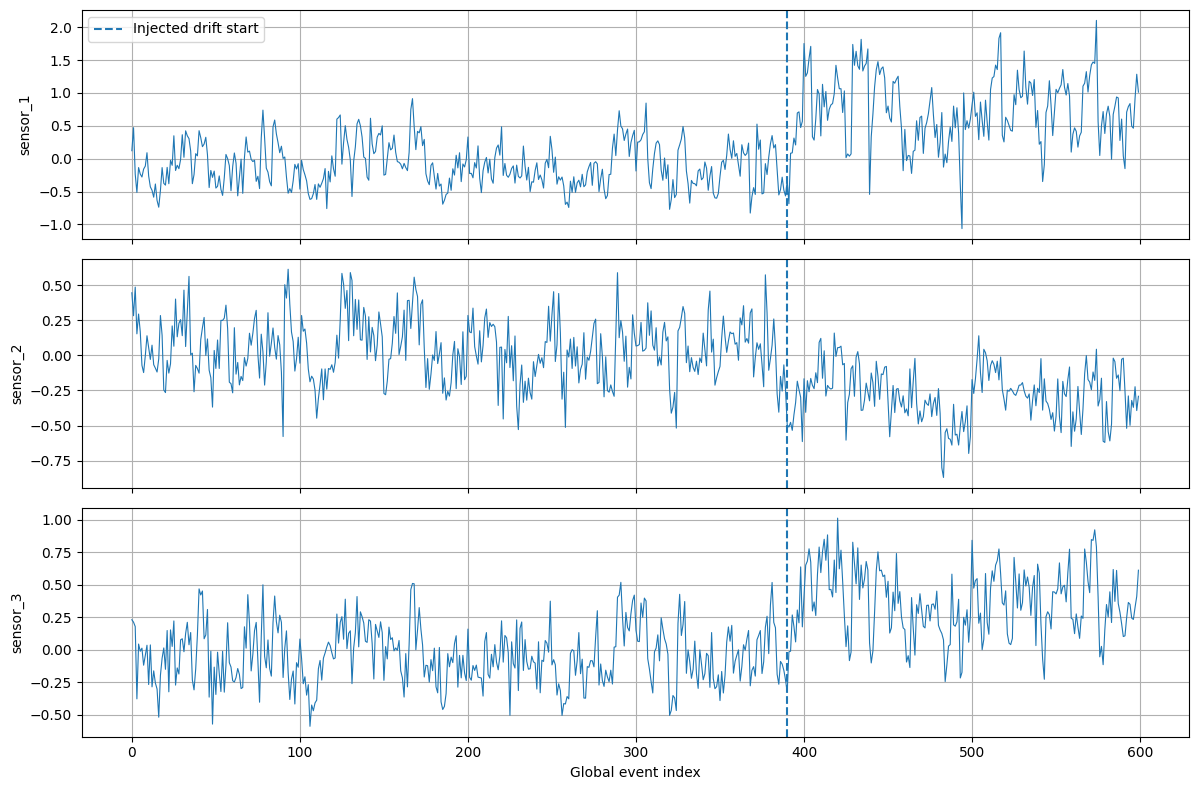

Injected drift events: 210


In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, ["sensor_1", "sensor_2", "sensor_3"]):
    ax.plot(stream["global_index"], stream[col], linewidth=0.8)
    ax.axvline(stream["drift_injected"].idxmax(), linestyle="--", label="Injected drift start")
    ax.set_ylabel(col)
    ax.grid(True)
axes[-1].set_xlabel("Global event index")
axes[0].legend()
plt.tight_layout()
plt.show()

print("Injected drift events:", int(stream["drift_injected"].sum()))

## 4. 시간순 분할 및 전처리

온라인 적응 시나리오를 반영하기 위해 과거 이벤트로 학습하고, 뒤쪽 이벤트를 순차 평가합니다.

정규화는 train 구간에만 fit합니다. 학습 중 미래 구간의 통계량을 사용하지 않습니다.

In [ ]:
train_z, val_z, test_z, x_scaler, y_scaler = transform_stream_splits(stream)
train_end = len(train_z)
val_end = train_end + len(val_z)
train_stream = stream.iloc[:train_end].copy()
val_stream = stream.iloc[train_end:val_end].copy()
test_stream = stream.iloc[val_end:].copy()

print("Split sizes:", len(train_stream), len(val_stream), len(test_stream))
print("Train drift fraction:", train_stream["drift_injected"].mean())
print("Test drift fraction:", test_stream["drift_injected"].mean())

Split sizes: 360 90 150
Train drift fraction: 0.0
Test drift fraction: 1.0


## 5. Rosenthal Physics Anchor

3D 이동 점열원에 대한 Rosenthal 근사식:

\[
T-T_0 = \frac{\eta P}{2\pi k R}
\exp\left[-\frac{v(x+R)}{2\alpha}\right]
\]

여기서 \(P\)는 레이저 출력, \(\eta\)는 유효 흡수율, \(k\)는 열전도도, \(\alpha\)는 열확산율입니다. 단면은 빔 중심 단면 \(x=0\)에서 평가하고, \(T \ge T_{liq}\)인 격자 영역을 용융 영역으로 근사합니다.

- \(R\)의 특이점을 완화하기 위해 유효 빔 반경을 사용합니다.
- 흡수율 \(\eta\)는 **train 구간에서만** 하나의 전역 스칼라로 보정합니다.
- 폭·깊이는 온도장 격자에서 추출하고, 단면적은 용융 격자 셀 면적의 합으로 계산합니다.
- 이 기준선은 Rosenthal 방정식에 기반하지만, 실제 분말층/상변화/유동을 완전히 해석하는 고충실도 모델은 아닙니다.


In [ ]:
# Fit one global effective absorptivity using training labels only.
calibration_frame = train_stream.reset_index(drop=True)
calibration_y = calibration_frame[TARGETS].to_numpy(float)
physics_anchor = RosenthalPhysicsAnchor.fit(calibration_frame)
ETA_EFFECTIVE = physics_anchor.eta
print(f"Train-calibrated effective absorptivity eta = {ETA_EFFECTIVE:.4f}")
print(f"Train calibration log-MSE = {physics_anchor.calibration_loss:.5f}")

anchor_all = physics_anchor.predict(stream)
stream[["anchor_W", "anchor_D", "anchor_A"]] = anchor_all

for part in (train_stream, val_stream, test_stream):
    anchors = physics_anchor.predict(part)
    part.loc[:, ["anchor_W", "anchor_D", "anchor_A"]] = anchors

train_z = add_scaled_anchors(train_z.merge(
    train_stream[["global_index", "anchor_W", "anchor_D", "anchor_A"]],
    on="global_index", how="left", validate="one_to_one"
))
val_z = add_scaled_anchors(val_z.merge(
    val_stream[["global_index", "anchor_W", "anchor_D", "anchor_A"]],
    on="global_index", how="left", validate="one_to_one"
))
test_z = add_scaled_anchors(test_z.merge(
    test_stream[["global_index", "anchor_W", "anchor_D", "anchor_A"]],
    on="global_index", how="left", validate="one_to_one"
))

print("Rosenthal Physics Anchor ready.")
display(stream[["anchor_W", "anchor_D", "anchor_A"]].describe().T)
print("Scaled Rosenthal anchor features added.")

Train-calibrated effective absorptivity eta = 0.9462
Train calibration log-MSE = 0.38511
Rosenthal Physics Anchor ready.


,count,mean,std,min,25%,50%,75%,max
anchor_W,600.0,125.40,43.871569,55.0,95.0,115.0,155.0,285.0
anchor_D,600.0,60.20,21.935784,25.0,45.0,55.0,75.0,140.0
anchor_A,600.0,7222.75,5057.714601,1400.0,3475.0,5550.0,9900.0,33225.0


Scaled Rosenthal anchor features added.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


## 6. 시퀀스 윈도우 구성

각 시점의 입력은 해당 job의 최근 `WINDOW_EVENTS` 이벤트입니다. train/validation/test 경계는 전역 시간 순서로 분리합니다. 여기서는 각 split 내부에서만 창을 만들므로, 경계 밖 미래 정보가 입력에 섞이지 않습니다.

In [ ]:
train_samples = make_windows(train_z)
val_samples = make_windows(val_z)
test_samples = make_windows(test_z)
print("Windows:", len(train_samples), len(val_samples), len(test_samples))

Windows: 360 90 150


## 7. Dataset / padding collator

In [ ]:
train_loader, val_loader, test_loader = make_loaders(
    train_samples, val_samples, test_samples, batch_size=BATCH_SIZE
)

## 8. Adaptive Physics-Residual LT

- GRU는 최근 이벤트 시퀀스를 인코딩합니다.
- Physics Anchor의 예측을 초기 상태로 사용합니다.
- 각 loop는 타깃별 gate와 **bounded residual correction**으로 폭·깊이·면적 예측을 반복 보정합니다.
- `return_loop_preds=True`로 loop별 예측을 관찰할 수 있습니다.
- uncertainty head는 최종 예측의 출력별 log-variance를 산출합니다.

이 모델은 이벤트가 도착할 때마다 호출됩니다. 이벤트 간 상태는 외부 State Manager가 유지하며, 모델 내부의 loop 상태를 다음 이벤트에 자동으로 전달하지는 않습니다. 즉, 각 이벤트에서 최근 이력으로 context를 다시 인코딩하고 내부 loop를 재실행합니다.


In [ ]:
model = AdaptivePhysicsResidualLT(
    input_dim=len(SEQUENCE_FEATURES), n_loops=N_LOOPS
).to(DEVICE)
b = next(iter(train_loader))
with torch.no_grad():
    pred, log_var, loop_preds = model(
        b["x"].to(DEVICE), b["mask"].to(DEVICE), b["anchor"].to(DEVICE),
        return_loop_preds=True,
    )
print("Prediction:", tuple(pred.shape))
print("Log variance:", tuple(log_var.shape))
print("Loop predictions:", tuple(loop_preds.shape))

Prediction: (64, 3)
Log variance: (64, 3)
Loop predictions: (64, 4, 3)


## 9. 학습

Epoch 001: train=0.4061, val=0.4546
Epoch 005: train=-0.0762, val=-0.0048
Epoch 010: train=-0.4436, val=-0.2033
Epoch 015: train=-0.6262, val=-0.2291
Epoch 020: train=-0.7146, val=-0.1927
Epoch 025: train=-0.8114, val=-0.1534
Early stopping at 29


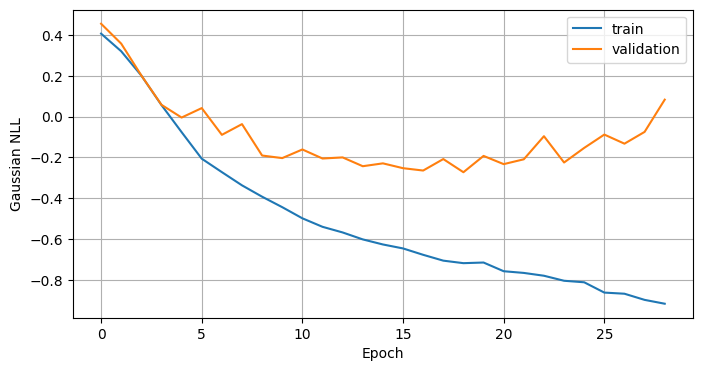

In [ ]:
history = fit_model(
    model, train_loader, val_loader, epochs=EPOCHS, patience=10
)

plt.figure(figsize=(8, 4))
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Gaussian NLL")
plt.legend()
plt.grid(True)
plt.show()

## 10. 성능 평가

예측은 표준화된 `log1p` 공간에서 출력되므로 원래 단위로 역변환합니다. 비교 기준:
- Rosenthal Physics Anchor (train 구간에서 유효 흡수율 1개만 보정)
- Adaptive Physics-Residual LT

이 비교는 합성 스트림에 대한 테스트입니다. 원본 행 재사용, 가상 센서 및 주입된 drift 때문에 실제 일반화 성능으로 해석하면 안 됩니다.


In [ ]:
pred_z, std_z, y_z, y_raw, drift_mask = predict_loader(model, test_loader)
pred_log = y_scaler.inverse_transform(pred_z)
pred_raw = np.maximum(np.expm1(pred_log), 0.0)
anchor_z = np.concatenate([batch["anchor"].numpy() for batch in test_loader], axis=0)
anchor_raw = np.maximum(np.expm1(y_scaler.inverse_transform(anchor_z)), 0.0)

metrics = metric_rows("Rosenthal Physics Anchor", y_raw, anchor_raw)
metrics += metric_rows("Adaptive Physics-Residual LT", y_raw, pred_raw)
metrics_df = pd.DataFrame(metrics)
display(metrics_df)
print("Test events:", len(y_raw), "Injected-drift events:", int(drift_mask.sum()))

,model,target,MAE,RMSE,R2
0,Rosenthal Physics Anchor,melt_width,44.551170,51.295866,-0.117670
1,Rosenthal Physics Anchor,melt_depth,71.996552,105.192017,-0.274441
2,Rosenthal Physics Anchor,melt_area,14130.031250,18529.140725,-0.365695
3,Adaptive Physics-Residual LT,melt_width,18.856499,24.265453,0.749893
4,Adaptive Physics-Residual LT,melt_depth,36.929996,54.230251,0.661283
5,Adaptive Physics-Residual LT,melt_area,5174.310547,7386.587033,0.782965


Test events: 150 Injected-drift events: 150


## 11. Online state와 drift monitor

여기서 구분하는 상태는 세 가지입니다.

1. **누적 이력:** 모든 이벤트를 저장소에 보존
2. **추론 윈도우:** 현재 job의 최근 `WINDOW_EVENTS`를 LT에 전달
3. **모델 파라미터:** 학습 완료 후 고정. 새 이벤트가 도착한다고 자동 재학습하지 않음

Drift score는 train 구간의 입력 분포와 현재 이벤트의 차이를 나타내는 간단한 지표이며, 실제 설비 적용 전에는 threshold를 검증해야 합니다.


,global_index,drift_injected,score,warning,history_events
0,450,True,1.683277,False,1
1,451,True,1.446441,False,2
2,452,True,1.345569,False,3
3,453,True,1.814938,False,4
4,454,True,1.837623,False,5


Warning rate: 0.0
Warning rate on injected-drift rows: 0.0
Warning rate before injected drift: nan


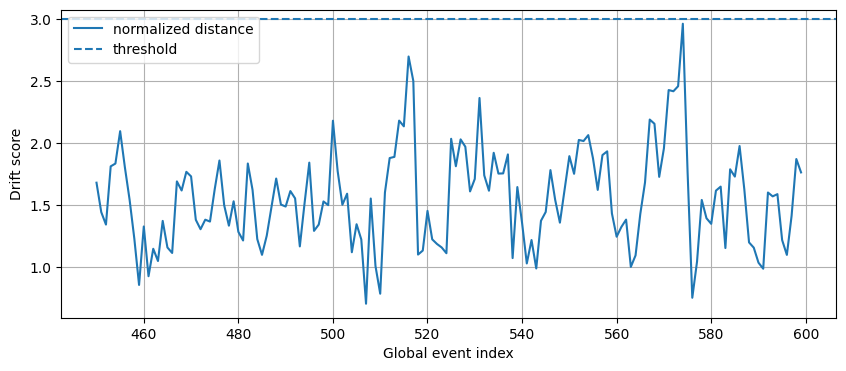

In [ ]:
ref = train_stream[INPUT_FEATURES].to_numpy()
monitor = SimpleDriftMonitor(ref, threshold=3.0)
monitor_rows = []
state = OnlineState()
for _, row in test_stream.iterrows():
    event = row.to_dict()
    hist = state.update(event)
    result = monitor.update(row[INPUT_FEATURES].to_numpy())
    monitor_rows.append({
        "global_index": int(row["global_index"]),
        "drift_injected": bool(row["drift_injected"]),
        "score": result["score"],
        "warning": result["warning"],
        "history_events": len(hist),
    })

monitor_df = pd.DataFrame(monitor_rows)
display(monitor_df.head())
print("Warning rate:", monitor_df["warning"].mean())
print("Warning rate on injected-drift rows:", monitor_df.loc[monitor_df["drift_injected"], "warning"].mean())
print("Warning rate before injected drift:", monitor_df.loc[~monitor_df["drift_injected"], "warning"].mean())

plt.figure(figsize=(10, 4))
plt.plot(monitor_df["global_index"], monitor_df["score"], label="normalized distance")
plt.axhline(monitor.threshold, linestyle="--", label="threshold")
plt.xlabel("Global event index")
plt.ylabel("Drift score")
plt.legend()
plt.grid(True)
plt.show()

## 12. 온라인 적응 해석

현재 State Update는 이벤트 이력을 갱신하지만 모델 가중치를 자동 업데이트하지 않습니다. 가중치 적응은 라벨 도착 정책과 데이터 품질 검증을 정의한 뒤 별도 비교해야 합니다.

- `Static`: train 구간에서 학습한 LT를 고정
- `Stateful`: 가중치는 고정하고 최신 이력을 입력
- `Online update`: 정답 라벨이 도착한 뒤 검증된 replay buffer로 제한적 업데이트
- `Drift-triggered update`: drift 경보 후 품질 검증을 통과한 샘플만 업데이트

정답 라벨이 없는 상태에서 모델 예측을 정답처럼 재학습하면 오차가 누적될 수 있습니다.


## 13. 재현성과 해석 주의

- Rosenthal 모델은 단순화된 이동 점열원 해석입니다. 분말층의 유효 열물성, 흡수율, 경계조건에 따라 geometry 추정치가 크게 달라집니다.
- `ETA_EFFECTIVE`는 train 구간에서만 보정합니다. 실제 공정 물성의 독립 측정값과 동일한 의미는 아닙니다.
- 격자 간격(`GRID_DY_UM`, `GRID_DZ_UM`)과 격자 범위는 속도·빔 직경·예상 용융풀 크기에 맞게 수렴성 검토가 필요합니다.
- 원본 정답 형상은 replay row에서 가져오며, 입력에 추가한 jitter가 정답 형상에 물리적으로 반영되지는 않습니다.
- 이 실험은 **실제 물리식 + LT 보정 구조의 코드 검증**이며, 실제 장비 검증을 대체하지 않습니다.


## 14. 실시간 이벤트 처리 서비스

`StreamingLTService`는 실시간 데이터 입력과 LT 추론을 연결합니다.

- 이벤트 수신 시 schema와 필수 feature를 검증
- `job_id`별 최근 이력을 유지하고 전체 이력을 저장
- 매 이벤트마다 Physics Anchor를 계산
- train에서 fit한 scaler로 입력을 변환
- 최근 이력으로 LT의 loop 1~N 추론을 수행
- 예측, loop별 출력, 불확실성, drift score를 결과로 반환
- SQLite에 원본 이벤트와 예측 결과를 누적 기록

실제 설비 연결 시에는 `process_event(event)`에 장비 어댑터가 만든 이벤트 dict를 전달하면 됩니다.


In [ ]:
# Reusable persistence and streaming inference implementations live in v5.service.
from model.LoopedTransformer.v5.service import SQLiteEventStore, StreamingLTService, run_stream_consumer

print("Streaming service module ready.")

## 15. Replay adapter — 기존 시뮬레이션 스트림을 실시간 입력처럼 재생

실제 장비 연결 전에는 test stream을 이벤트 단위로 전달해 인터페이스를 검증합니다. 각 이벤트가 도착할 때마다 LT를 호출하며, 전체 이력은 SQLite에 누적하고 최근 윈도우만 모델 입력으로 사용합니다.


In [ ]:
STREAM_DB_PATH = str(repo_root / "model/LoopedTransformer/V5_stream/v5_replay.sqlite")

service = StreamingLTService(
    model=model,
    x_scaler=x_scaler,
    y_scaler=y_scaler,
    physics_anchor=physics_anchor,
    reference_X=train_stream[INPUT_FEATURES].to_numpy(),
    db_path=STREAM_DB_PATH,
    window_events=WINDOW_EVENTS,
    drift_threshold=3.0,
)

replay_outputs = []
for _, row in test_stream.iterrows():
    event = row.to_dict()
    event["event_id"] = f"{event['job_id']}:{int(event['global_index'])}"
    event["timestamp"] = (
        pd.Timestamp("2026-01-01T00:00:00Z")
        + pd.Timedelta(seconds=float(event["global_index"]))
    ).isoformat()
    replay_outputs.append(service.process_event(event))

replay_df = pd.DataFrame([
    {
        "event_id": output["event_id"],
        "job_id": output["job_id"],
        "history_events": output["history_events"],
        **{f"Pred_{key}": value for key, value in output["prediction"].items()},
        **{f"Anchor_{key}": value for key, value in output["anchor"].items()},
        "drift_score": output["drift_score"],
        "drift_warning": output["drift_warning"],
    }
    for output in replay_outputs
])
display(replay_df.head(10))
print("Replayed events:", len(replay_df))
print("SQLite path:", STREAM_DB_PATH)
print("Predictions persisted:", len(service.store.read_predictions(limit=len(replay_df))))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,event_id,job_id,history_events,Pred_melt_width,Pred_melt_depth,Pred_melt_area,Anchor_melt_width,Anchor_melt_depth,Anchor_melt_area,drift_score,drift_warning
0,job_018:450,job_018,1,165.205658,99.089928,15634.019531,155.0,75.0,9450.0,1.683277,False
1,job_018:451,job_018,2,184.080856,134.358017,23745.367188,175.0,85.0,12200.0,1.446441,False
2,job_018:452,job_018,3,190.275360,100.172699,21951.794922,185.0,90.0,14225.0,1.345569,False
3,job_018:453,job_018,4,227.821869,158.095291,33381.742188,215.0,105.0,17900.0,1.814938,False
4,job_018:454,job_018,5,228.193802,208.848022,41283.226562,215.0,105.0,17900.0,1.837623,False
5,job_018:455,job_018,6,215.502609,175.183228,34682.835938,195.0,95.0,15300.0,2.098664,False
6,job_018:456,job_018,7,206.481262,161.733047,30110.691406,185.0,90.0,13475.0,1.807760,False
7,job_018:457,job_018,8,176.309875,93.285652,16753.517578,155.0,75.0,9350.0,1.545460,False
8,job_018:458,job_018,8,213.949234,159.874741,32122.134766,205.0,100.0,16425.0,1.231728,False
9,job_018:459,job_018,8,162.963165,61.161270,12733.792969,135.0,65.0,7750.0,0.858829,False


Replayed events: 150
SQLite path: physical_ai_stream_demo.sqlite
Predictions persisted: 150


## 16. Queue consumer — 실제 adapter 연결 지점

실제 장비 adapter 또는 MQTT/OPC-UA 수신기가 `event_queue.put(event)`를 호출하면 아래 consumer가 이벤트를 받아 `process_event`로 전달합니다. 이 셀은 함수를 정의만 하며, 무한 consumer를 자동 실행하지 않습니다.


In [ ]:
# run_stream_consumer is imported from v5.service and starts only when called.

## 17. 운영상 핵심 구분과 한계

- **모델 내부 반복:** 한 이벤트 입력에 대해 Loop 1~N을 실행해 현재 예측을 보정합니다.
- **이벤트 반복:** 새 이벤트가 도착할 때마다 최신 rolling history로 모델을 다시 호출합니다.
- **누적 저장:** 모든 이벤트와 예측을 SQLite에 보존합니다. 전체 데이터베이스를 매번 모델에 넣지는 않습니다.
- **온라인 학습:** 이 노트북에서는 실행하지 않습니다. 가중치는 고정이고 `model_updated=False`로 기록합니다.
- **입력 계약:** 실시간 adapter는 학습 시 사용한 `PROCESS_FEATURES`, 센서 채널 및 단위와 일치해야 합니다.
- **시간 특성:** 현재 학습 입력은 최근 최대 8개 이벤트입니다. 실제 운영에서 더 긴 시간 이력을 쓰려면 모델을 그 입력 구조로 재학습하고 검증해야 합니다.
- **정답 지연:** 실제 용융풀 측정 결과가 나중에 도착한다면 `event_id`로 예측과 연결해 사후 평가해야 합니다.
- **물리 모델:** Rosenthal은 저차 근사식입니다. 실제 LPBF의 용융풀 유동, 상변화, keyhole dynamics를 완전하게 해석하지 않습니다.
- **안전:** 설비 제어 명령을 직접 실행하지 않습니다. 향후 제어 연결은 별도 검증, 제한 조건, 승인 절차를 갖춰야 합니다.


## 18. 모델·전처리 아티팩트 저장

실시간 추론 프로세스를 노트북 학습 세션과 분리할 수 있도록 모델 가중치, scaler, 설정을 저장합니다. 운영 환경에서는 모델 코드 버전과 scaler 버전을 함께 관리해야 합니다.


In [ ]:
ARTIFACT_DIR = save_artifacts(
    model=model,
    x_scaler=x_scaler,
    y_scaler=y_scaler,
    eta=ETA_EFFECTIVE,
    output_dir=Path("physical_ai_lt_artifacts"),
)
print("Saved artifacts to:", ARTIFACT_DIR.resolve())

Saved artifacts to: /content/physical_ai_lt_artifacts
